# RoadScan: freeze run-17 confidence before local testing

Choose a single operating confidence for the adopted fine-tuned checkpoint using China development validation only. No retraining, US or local test data. mAP is unchanged by this operating-point selection. Preserve the published initialization attribution.

## 1. Verify inputs and predeclare the policy

Load the frozen run-17 model, verify its hash and record a pothole-recall target of 90% before viewing the sweep. This balances missed potholes against false alarms through the Macro-F1 objective.

In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, math
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'])
from ultralytics import YOLO
import torch
assert torch.cuda.is_available(), 'Enable GPU.'
BASE=Path('/kaggle/input/notebooks/rimasabunasser/17-roadscan-gentle-finetuning')
DATA=BASE/'run17_team_v2_data/val'
WEIGHTS=BASE/'run17_model_comparison/run17_best_finetuned.pt'
EXPECTED_SHA='25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f'
assert hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()==EXPECTED_SHA
assert len(list((DATA/'images').glob('*.jpg')))==1977
OUT=Path('/kaggle/working/threshold_run17');OUT.mkdir(exist_ok=True)
CLASSES=['D00','D10','D20','D40']
# Predeclare the operating-point policy before inspecting scores.
POLICY=dict(objective='maximize unweighted mean of four box-level F1 scores',pothole_recall_floor=0.90,matching_iou=0.50,nms_iou=0.70,max_det=300,imgsz=640,grid='0.001 plus 0.01..0.95, step 0.01',ties='higher pothole recall, then higher confidence',fallback='if recall floor impossible: maximize pothole recall, then macro-F1, then higher confidence; explicitly record unmet floor')
(OUT/'selection_policy.json').write_text(json.dumps(POLICY,indent=2))
model=YOLO(str(WEIGHTS))
assert [model.names[i] for i in range(4)]==CLASSES
print('THRESHOLD_SETUP_READY',json.dumps(POLICY),flush=True)
display(Markdown('**Setup interpretation.** The adopted fine-tuned run-17 checkpoint and all 1,977 China development images are present. The selection policy is recorded before evaluation: maximize box Macro-F1 while retaining at least 90% pothole recall if feasible. No local or US test data is opened. This recall floor is an engineering target on development data, not a guarantee on local roads.'))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 4.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
THRESHOLD_SETUP_READY {"objective": "maximize unweighted mean of four box-level F1 scores", "pothole_recall_floor": 0.9, "matching_iou": 0.5, "nms_iou": 0.7, "max_det": 300, "imgsz": 640, "grid": "0.001 plus 0.01..0.95, step 0.01", "ties": "higher pothole recall, then higher confidence", "fallback": "if recall floor impossible: maximize pothole recall, then macro-F1, then higher confidence; explicitly record unmet floor"}


**Setup interpretation.** The adopted fine-tuned run-17 checkpoint and all 1,977 China development images are present. The selection policy is recorded before evaluation: maximize box Macro-F1 while retaining at least 90% pothole recall if feasible. No local or US test data is opened. This recall floor is an engineering target on development data, not a guarantee on local roads.

## 2. Collect validation detections

Run fixed 640-pixel inference with NMS IoU 0.7 and a low confidence floor. Match predictions to same-class labels one-to-one at IoU 0.5. Duplicate and wrong-class detections count as false positives. This explicitly documented box-level evaluator differs from image-level presence F1.

In [2]:
def box_iou_one(box, targets):
    if len(targets)==0: return np.empty(0)
    wh=np.maximum(0,np.minimum(box[2:],targets[:,2:])-np.maximum(box[:2],targets[:,:2]))
    intersection=wh[:,0]*wh[:,1]
    area=(box[2]-box[0])*(box[3]-box[1])
    areas=(targets[:,2]-targets[:,0])*(targets[:,3]-targets[:,1])
    return intersection/np.maximum(area+areas-intersection,1e-12)

def match_image(pred, gt):
    # pred: x1,y1,x2,y2,confidence,class; gt: x1,y1,x2,y2,class.
    # Descending-confidence, same-class, greedy one-to-one IoU>=0.5.
    # A duplicate or wrong-class box is a false positive. Unmatched labels are FN.
    matched=set(); rows=[]
    for p in pred[np.argsort(-pred[:,4],kind='stable')]:
        ids=[i for i,g in enumerate(gt) if int(g[4])==int(p[5]) and i not in matched]
        true_positive=False
        if ids:
            overlaps=box_iou_one(p[:4],gt[ids,:4]);best=int(np.argmax(overlaps))
            if overlaps[best]>=0.5: matched.add(ids[best]);true_positive=True
        rows.append((float(p[4]),int(p[5]),int(true_positive)))
    return rows
# Minimal correctness checks cover duplicate boxes, class mismatch and backgrounds.
tgt=np.array([[0,0,10,10,3]],dtype=float)
assert match_image(np.array([[0,0,10,10,.9,3],[0,0,10,10,.8,3]],dtype=float),tgt)==[(.9,3,1),(.8,3,0)]
assert match_image(np.array([[0,0,10,10,.9,0]],dtype=float),tgt)==[(.9,0,0)]
assert match_image(np.empty((0,6)),tgt)==[]
assert match_image(np.array([[0,0,10,10,.9,3]],dtype=float),np.empty((0,5)))==[(.9,3,0)]
assert np.allclose(box_iou_one(np.array([0,0,10,10]),tgt[:,:4]),[1.0])
records=[]; supports=np.zeros(4,dtype=int);seen=[]
for idx,result in enumerate(model.predict(source=str(DATA/'images'),imgsz=640,conf=0.001,iou=0.7,max_det=300,device=0,stream=True,verbose=False),1):
    stem=Path(result.path).stem;seen.append(stem)
    label=DATA/'labels'/(stem+'.txt'); assert label.is_file()
    h,w=result.orig_shape;gt=[]
    for line in label.read_text().splitlines():
        if not line.strip():continue
        c,x,y,bw,bh=map(float,line.split());c=int(c);supports[c]+=1
        gt.append([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h,c])
    pred=result.boxes.data.cpu().numpy()
    assert pred.shape[1]==6
    records.extend(match_image(pred,np.asarray(gt,dtype=float).reshape(-1,5)))
    if idx%250==0: print('VALIDATION_IMAGES_PROCESSED',idx,flush=True)
assert len(seen)==len(set(seen))==1977
assert supports.tolist()==[2678,1096,641,235],supports
records=np.asarray(records,dtype=float).reshape(-1,3)
np.savez_compressed(OUT/'matched_detections.npz',confidence=records[:,0],class_id=records[:,1].astype(int),true_positive=records[:,2].astype(int),supports=supports,image_stems=np.array(sorted(seen)))
print('VALIDATION_PREDICTIONS_READY',len(records),'boxes above 0.001',flush=True)
display(Markdown('**Inference interpretation.** All 1,977 images were processed. Ground-truth counts match the saved run-17 evaluation. Matching is class-aware, one-to-one and uses IoU 0.5. Confidence filtering is applied after fixed NMS, so the same detections are reused for every candidate threshold. This is an explicitly documented operating-point evaluator; it does not replace the official mAP evaluation.'))


VALIDATION_IMAGES_PROCESSED 250
VALIDATION_IMAGES_PROCESSED 500
VALIDATION_IMAGES_PROCESSED 750
VALIDATION_IMAGES_PROCESSED 1000
VALIDATION_IMAGES_PROCESSED 1250
VALIDATION_IMAGES_PROCESSED 1500
VALIDATION_IMAGES_PROCESSED 1750
VALIDATION_PREDICTIONS_READY 107041 boxes above 0.001


**Inference interpretation.** All 1,977 images were processed. Ground-truth counts match the saved run-17 evaluation. Matching is class-aware, one-to-one and uses IoU 0.5. Confidence filtering is applied after fixed NMS, so the same detections are reused for every candidate threshold. This is an explicitly documented operating-point evaluator; it does not replace the official mAP evaluation.

## 3. Compare candidate thresholds

Sweep confidence from 0.01 to 0.95 plus 0.001, compare with 0.25, and apply the predeclared policy. Report per-class counts and the precision/recall trade-off, including whether the recall target is feasible.

,confidence,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,pothole_precision,pothole_recall,pothole_f1,false_positives,false_negatives,false_positives_per_100_images
previous 0.25,0.25,0.795483,0.945795,0.862661,0.752972,0.926237,0.830665,0.876923,0.970213,0.921212,1413,343,71.471927
chosen,0.46,0.905904,0.886737,0.895562,0.892906,0.844516,0.868037,0.941909,0.965957,0.953782,471,723,23.823976
unconstrained best F1,0.46,0.905904,0.886737,0.895562,0.892906,0.844516,0.868037,0.941909,0.965957,0.953782,471,723,23.823976


,damage_code,TP,FP,FN,precision,recall,f1,support
0,D00,2215,270,463,0.891348,0.827110,0.858028,2678
1,D10,869,140,227,0.861249,0.792883,0.825653,1096
2,D20,616,47,25,0.929110,0.960998,0.944785,641
3,D40,227,14,8,0.941909,0.965957,0.953782,235


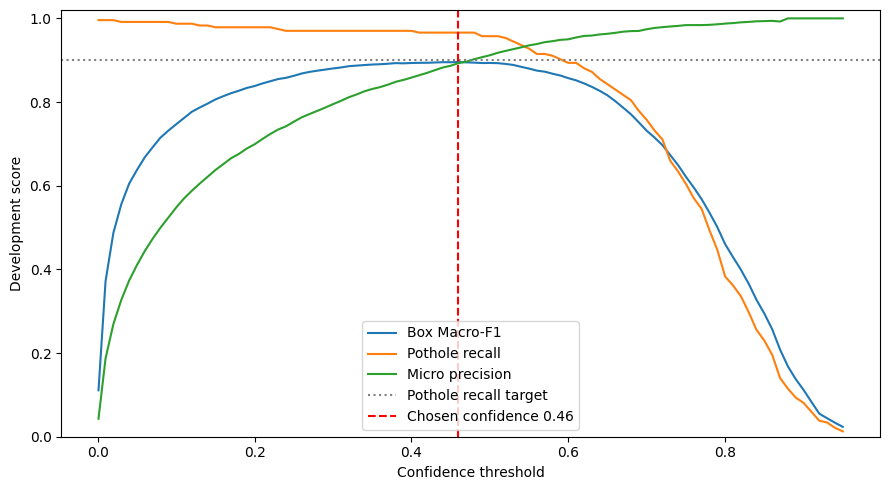

THRESHOLD_SELECTED 0.46 POTHOLE_RECALL_FLOOR_MET True


**Selection interpretation.** Chosen confidence is **0.46**. Box Macro-F1 is **89.56%**, micro precision **89.29%**, micro recall **84.45%**, and pothole recall **96.60%**. The 90% pothole-recall target was met. These scores are development estimates tuned on this same set, not independent test results. A higher count of predictions alone is not an improvement.

In [3]:
def metrics_at(threshold):
    kept=records[records[:,0]>=threshold];rows=[]
    for c,name in enumerate(CLASSES):
        cls=kept[kept[:,1]==c];tp=int(cls[:,2].sum());fp=len(cls)-tp;fn=int(supports[c])-tp
        precision=tp/(tp+fp) if tp+fp else 0.0
        recall=tp/int(supports[c]);f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
        rows.append(dict(damage_code=name,TP=tp,FP=fp,FN=fn,precision=precision,recall=recall,f1=f1,support=int(supports[c])))
    tp=sum(r['TP'] for r in rows);fp=sum(r['FP'] for r in rows);fn=sum(r['FN'] for r in rows)
    return dict(confidence=float(threshold),macro_precision=float(np.mean([r['precision'] for r in rows])),macro_recall=float(np.mean([r['recall'] for r in rows])),macro_f1=float(np.mean([r['f1'] for r in rows])),micro_precision=tp/(tp+fp) if tp+fp else 0.0,micro_recall=tp/(tp+fn),micro_f1=2*tp/(2*tp+fp+fn),pothole_precision=rows[3]['precision'],pothole_recall=rows[3]['recall'],pothole_f1=rows[3]['f1'],false_positives=fp,false_negatives=fn,false_positives_per_100_images=100*fp/1977,per_class=rows)
grid=[0.001]+[round(float(x),2) for x in np.arange(0.01,0.951,0.01)]
metrics=[metrics_at(t) for t in grid]
feasible=[r for r in metrics if r['pothole_recall']>=0.90]
if feasible:
    chosen=max(feasible,key=lambda r:(r['macro_f1'],r['pothole_recall'],r['confidence']));floor_met=True
else:
    chosen=max(metrics,key=lambda r:(r['pothole_recall'],r['macro_f1'],r['confidence']));floor_met=False
baseline=metrics_at(0.25)
unconstrained=max(metrics,key=lambda r:(r['macro_f1'],r['pothole_recall'],r['confidence']))
flat=pd.DataFrame([{k:v for k,v in r.items() if k!='per_class'} for r in metrics]);flat.to_csv(OUT/'threshold_sweep.csv',index=False)
pd.DataFrame(chosen['per_class']).to_csv(OUT/'chosen_per_class.csv',index=False)
display(pd.DataFrame([{k:v for k,v in r.items() if k!='per_class'} for r in [baseline,chosen,unconstrained]],index=['previous 0.25','chosen','unconstrained best F1']))
display(pd.DataFrame(chosen['per_class']))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,5));ax.plot(flat.confidence,flat.macro_f1,label='Box Macro-F1');ax.plot(flat.confidence,flat.pothole_recall,label='Pothole recall');ax.plot(flat.confidence,flat.micro_precision,label='Micro precision');ax.axhline(.90,color='grey',linestyle=':',label='Pothole recall target');ax.axvline(chosen['confidence'],color='red',linestyle='--',label=f"Chosen confidence {chosen['confidence']:.2f}");ax.set(xlabel='Confidence threshold',ylabel='Development score',ylim=(0,1.02));ax.legend();fig.tight_layout();fig.savefig(OUT/'threshold_selection.png',dpi=150);display(fig);plt.close(fig)
print('THRESHOLD_SELECTED',chosen['confidence'],'POTHOLE_RECALL_FLOOR_MET',floor_met,flush=True)
display(Markdown(f"**Selection interpretation.** Chosen confidence is **{chosen['confidence']:.2f}**. Box Macro-F1 is **{chosen['macro_f1']:.2%}**, micro precision **{chosen['micro_precision']:.2%}**, micro recall **{chosen['micro_recall']:.2%}**, and pothole recall **{chosen['pothole_recall']:.2%}**. The 90% pothole-recall target was {'met' if floor_met else 'NOT met; the recorded fallback was used'}. These scores are development estimates tuned on this same set, not independent test results. A higher count of predictions alone is not an improvement."))


## 4. Freeze and verify inference

Save the decision, full sweep, model settings and updated detector default. Verify the default on the actual checkpoint. Freeze settings before the independent local evaluation.

In [4]:
module_source='"""Single-image YOLO inference returning RDD2022 D codes and pixel boxes."""\nfrom pathlib import Path\nimport math\n\n_NAME_TO_CODE = {\n    \'d00\': \'D00\', \'longitudinal_crack\': \'D00\',\n    \'d10\': \'D10\', \'transverse_crack\': \'D10\',\n    \'d20\': \'D20\', \'alligator_crack\': \'D20\',\n    \'d40\': \'D40\', \'pothole\': \'D40\',\n}\n\n\nclass RoadDamageDetector:\n    """Load a local four-class checkpoint once, then call detect_damage(image).\n\n    image: a local image path, PIL image, or OpenCV BGR numpy array.\n    Output: JSON-compatible detections; bbox_xyxy is in original-image pixels.\n    An empty list means no detection above the threshold, not a verified safe road.\n    """\n\n    def __init__(self, weights, *, device=\'cpu\', imgsz=640):\n        weights = Path(weights)\n        if not weights.is_file():\n            raise FileNotFoundError(f\'Checkpoint not found: {weights}\')\n        if not isinstance(imgsz, int) or isinstance(imgsz, bool) or imgsz <= 0:\n            raise ValueError(\'imgsz must be a positive integer.\')\n        from ultralytics import YOLO\n        self._model = YOLO(str(weights))\n        self.device = device\n        self.imgsz = imgsz\n        names = self._model.names\n        names = dict(enumerate(names)) if isinstance(names, (list, tuple)) else names\n        try:\n            self._codes = {int(i): _NAME_TO_CODE[str(name).strip().lower()]\n                           for i, name in names.items()}\n        except (KeyError, TypeError, ValueError) as exc:\n            raise ValueError(\'Expected D00/D10/D20/D40 or the published semantic class names; incompatible checkpoint.\') from exc\n        if len(self._codes) != 4 or set(self._codes.values()) != {\'D00\', \'D10\', \'D20\', \'D40\'}:\n            raise ValueError(\'Checkpoint must contain each of the four RDD2022 damage classes exactly once.\')\n\n    def detect_damage(self, image, *, confidence=0.25, iou=0.7):\n        """Return every retained damage as damage_code, bbox_xyxy, confidence.\n\n        confidence=0.25 is provisional, not a validated deployment threshold.\n        Invalid/unreadable images raise an exception, rather than returning [].\n        """\n        for name, value in [(\'confidence\', confidence), (\'iou\', iou)]:\n            if not isinstance(value, (int, float)) or not math.isfinite(value) or not 0 <= value <= 1:\n                raise ValueError(f\'{name} must be between 0 and 1.\')\n        if image is None or isinstance(image, (list, tuple, int, float)):\n            raise TypeError(\'Pass one local image path, PIL image, or OpenCV BGR numpy array.\')\n        if isinstance(image, (str, Path)):\n            from PIL import Image\n            with Image.open(image) as opened:\n                image = opened.convert(\'RGB\')\n        else:\n            # PIL images use RGB; numpy input follows Ultralytics OpenCV BGR convention.\n            from PIL import Image\n            import numpy as np\n            if isinstance(image, Image.Image):\n                image = image.convert(\'RGB\')\n            elif not isinstance(image, np.ndarray) or image.ndim != 3 or image.shape[2] != 3 or image.size == 0:\n                raise TypeError(\'Array input must be a nonempty H x W x 3 BGR image.\')\n        results = self._model.predict(source=image, imgsz=self.imgsz,\n                                      conf=confidence, iou=iou, max_det=300,\n                                      device=self.device, verbose=False)\n        if len(results) != 1:\n            raise ValueError(\'Expected exactly one image result.\')\n        boxes = results[0].boxes\n        if boxes is None:\n            return []\n        detections = []\n        for xyxy, cls_id, score in zip(boxes.xyxy.cpu().tolist(),\n                                       boxes.cls.cpu().tolist(),\n                                       boxes.conf.cpu().tolist()):\n            detections.append({\n                \'damage_code\': self._codes[int(cls_id)],\n                \'bbox_xyxy\': [float(v) for v in xyxy],\n                \'confidence\': float(score),\n            })\n        return detections\n'
threshold=chosen['confidence']
module_source=module_source.replace('import math\n','import math\n\nDEFAULT_CONFIDENCE = '+repr(threshold)+'\n',1)
module_source=module_source.replace('confidence=0.25, iou=0.7','confidence=DEFAULT_CONFIDENCE, iou=0.7')
module_source=module_source.replace('confidence=0.25 is provisional, not a validated deployment threshold.','The default confidence was frozen on China development data before local testing.')
(OUT/'roadscan_detector.py').write_text(module_source)
config=dict(model='YOLOv8s',project_checkpoint='run17_best_finetuned.pt',kaggle_relative_path='run17_model_comparison/run17_best_finetuned.pt',sha256=EXPECTED_SHA,run=17,source_version=362779073,class_mapping=dict(enumerate(CLASSES)),imgsz=640,confidence=threshold,confidence_status='frozen on China development validation before independent local test',iou=0.7,max_det=300,matching_iou_for_selection=0.5,selection_policy=POLICY,validation_images=1977,pothole_recall_floor_met=floor_met,independent_local_generalization_evaluated=False,original_checkpoint_role='reference only')
(OUT/'model_config.json').write_text(json.dumps(config,indent=2))
import importlib.util
spec=importlib.util.spec_from_file_location('frozen_detector',OUT/'roadscan_detector.py');module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
frozen=module.RoadDamageDetector(WEIGHTS,device='cpu')
path=DATA/'images'/(sorted(seen)[0]+'.jpg')
a=frozen.detect_damage(path);b=frozen.detect_damage(path,confidence=threshold)
assert a==b
assert all(x['damage_code'] in CLASSES and x['confidence']>=threshold for x in a)
summary=dict(status='complete',model_checkpoint='run17_best_finetuned.pt',checkpoint_sha256=EXPECTED_SHA,confidence=threshold,config=config,selection_policy=POLICY,chosen=chosen,previous_0_25=baseline,unconstrained_best=unconstrained,recall_floor_met=floor_met,module_sha256=hashlib.sha256(module_source.encode()).hexdigest(),frozen_default_real_inference_passed=True,scope='development-only operating-point selection; external pretraining overlap unknown; not independent local accuracy',local_images_used=False,US_images_used=False,training_performed=False)
(OUT/'threshold_selection_results.json').write_text(json.dumps(summary,indent=2))
report=f"# Frozen run-17 confidence threshold\n\nAdopted fine-tuned checkpoint SHA-256: `{EXPECTED_SHA}`. Confidence: **{threshold:.2f}**; imgsz 640, NMS IoU 0.7, max_det 300.\n\nPolicy: maximize box Macro-F1 with pothole recall >=90% on 1,977 China development images when feasible. Matching uses descending-confidence same-class greedy one-to-one IoU >=0.5. Grid: 0.001 plus 0.01..0.95. Floor met: {floor_met}.\n\nChosen box Macro-F1: {chosen['macro_f1']:.4f}; micro precision: {chosen['micro_precision']:.4f}; micro recall: {chosen['micro_recall']:.4f}; pothole recall: {chosen['pothole_recall']:.4f}. Prior confidence 0.25 box Macro-F1: {baseline['macro_f1']:.4f}; pothole recall: {baseline['pothole_recall']:.4f}.\n\nThe saved detector default matches the frozen configuration and was verified against explicit-threshold inference on the real checkpoint. This selection does not change trained weights. External pretraining overlap remains unknown; development scores are optimistic after threshold selection. Do not tune on the final local test. Preserve source attribution.\n"
(OUT/'THRESHOLD_SELECTION.md').write_text(report)
display(Markdown('**Freeze interpretation.** The chosen threshold is saved in both `model_config.json` and the detector function default. Actual CPU inference confirmed that the default and explicit threshold return identical results. Keep checkpoint, resolution, NMS and confidence fixed for the independent labeled local test. This does not establish generalization.'))
print('THRESHOLD_FREEZE_COMPLETE',json.dumps(summary),flush=True)


**Freeze interpretation.** The chosen threshold is saved in both `model_config.json` and the detector function default. Actual CPU inference confirmed that the default and explicit threshold return identical results. Keep checkpoint, resolution, NMS and confidence fixed for the independent labeled local test. This does not establish generalization.

THRESHOLD_FREEZE_COMPLETE {"status": "complete", "model_checkpoint": "run17_best_finetuned.pt", "checkpoint_sha256": "25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f", "confidence": 0.46, "config": {"model": "YOLOv8s", "project_checkpoint": "run17_best_finetuned.pt", "kaggle_relative_path": "run17_model_comparison/run17_best_finetuned.pt", "sha256": "25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f", "run": 17, "source_version": 362779073, "class_mapping": {"0": "D00", "1": "D10", "2": "D20", "3": "D40"}, "imgsz": 640, "confidence": 0.46, "confidence_status": "frozen on China development validation before independent local test", "iou": 0.7, "max_det": 300, "matching_iou_for_selection": 0.5, "selection_policy": {"objective": "maximize unweighted mean of four box-level F1 scores", "pothole_recall_floor": 0.9, "matching_iou": 0.5, "nms_iou": 0.7, "max_det": 300, "imgsz": 640, "grid": "0.001 plus 0.01..0.95, step 0.01", "ties": "higher pothole recall, then